# SIAP — Bilingual Complaint Classifier (English + Indonesian)

Classifies a student complaint into one of 11 categories, scores its urgency (1–10), and routes it to the responsible department. Works on English and Indonesian text.

In [1]:
import os
import re
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedGroupKFold, cross_val_score
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.svm import LinearSVC
from sklearn.metrics import classification_report, confusion_matrix, f1_score, accuracy_score

## Dataset

`combined_dataset_bilingual_full.csv` holds every complaint in English and Indonesian (each Indonesian row is a translation of an English one). `Source_EN` is the original English text, used as a **group ID** so a complaint and its translation always land on the same side of the train/test split. Otherwise the model could see a complaint in English during training and its translation during testing, which inflates the score.

In [2]:
raw = pd.read_csv('combined_dataset_bilingual_full.csv')
data = raw.rename(columns={'Source_EN': 'group', 'Language': 'lang', 'Reports': 'text', 'Genre': 'genre'})
data = data[['group', 'lang', 'text', 'genre']]
data['text'] = data['text'].str.strip()

# Remove duplicates, generator leftovers, and texts that appear with more than one label
data = data.drop_duplicates(['text', 'genre'])
data = data[~data['text'].str.contains('hypothetical reports|laporan hipotetis', case=False)]
n_labels = data.groupby('text')['genre'].nunique()
data = data[data['text'].isin(n_labels[n_labels == 1].index)].reset_index(drop=True)

print(data['lang'].value_counts())
print(f"Unique complaint groups: {data['group'].nunique()}")


lang
en    2927
id    2906
Name: count, dtype: int64
Unique complaint groups: 2927


## EDA

lang                                en   id
genre                                      
Academic Support and Resources     462  458
Athletics and sports               179  179
Financial Support                  280  280
Food and Cantines                  210  206
Health and Well-being Support      161  159
Housing and Transportation         533  529
International student experiences  174  171
Internship Opportunities           171  170
Online learning                    314  314
Student Activities                 130  130
Student Affairs                    313  310


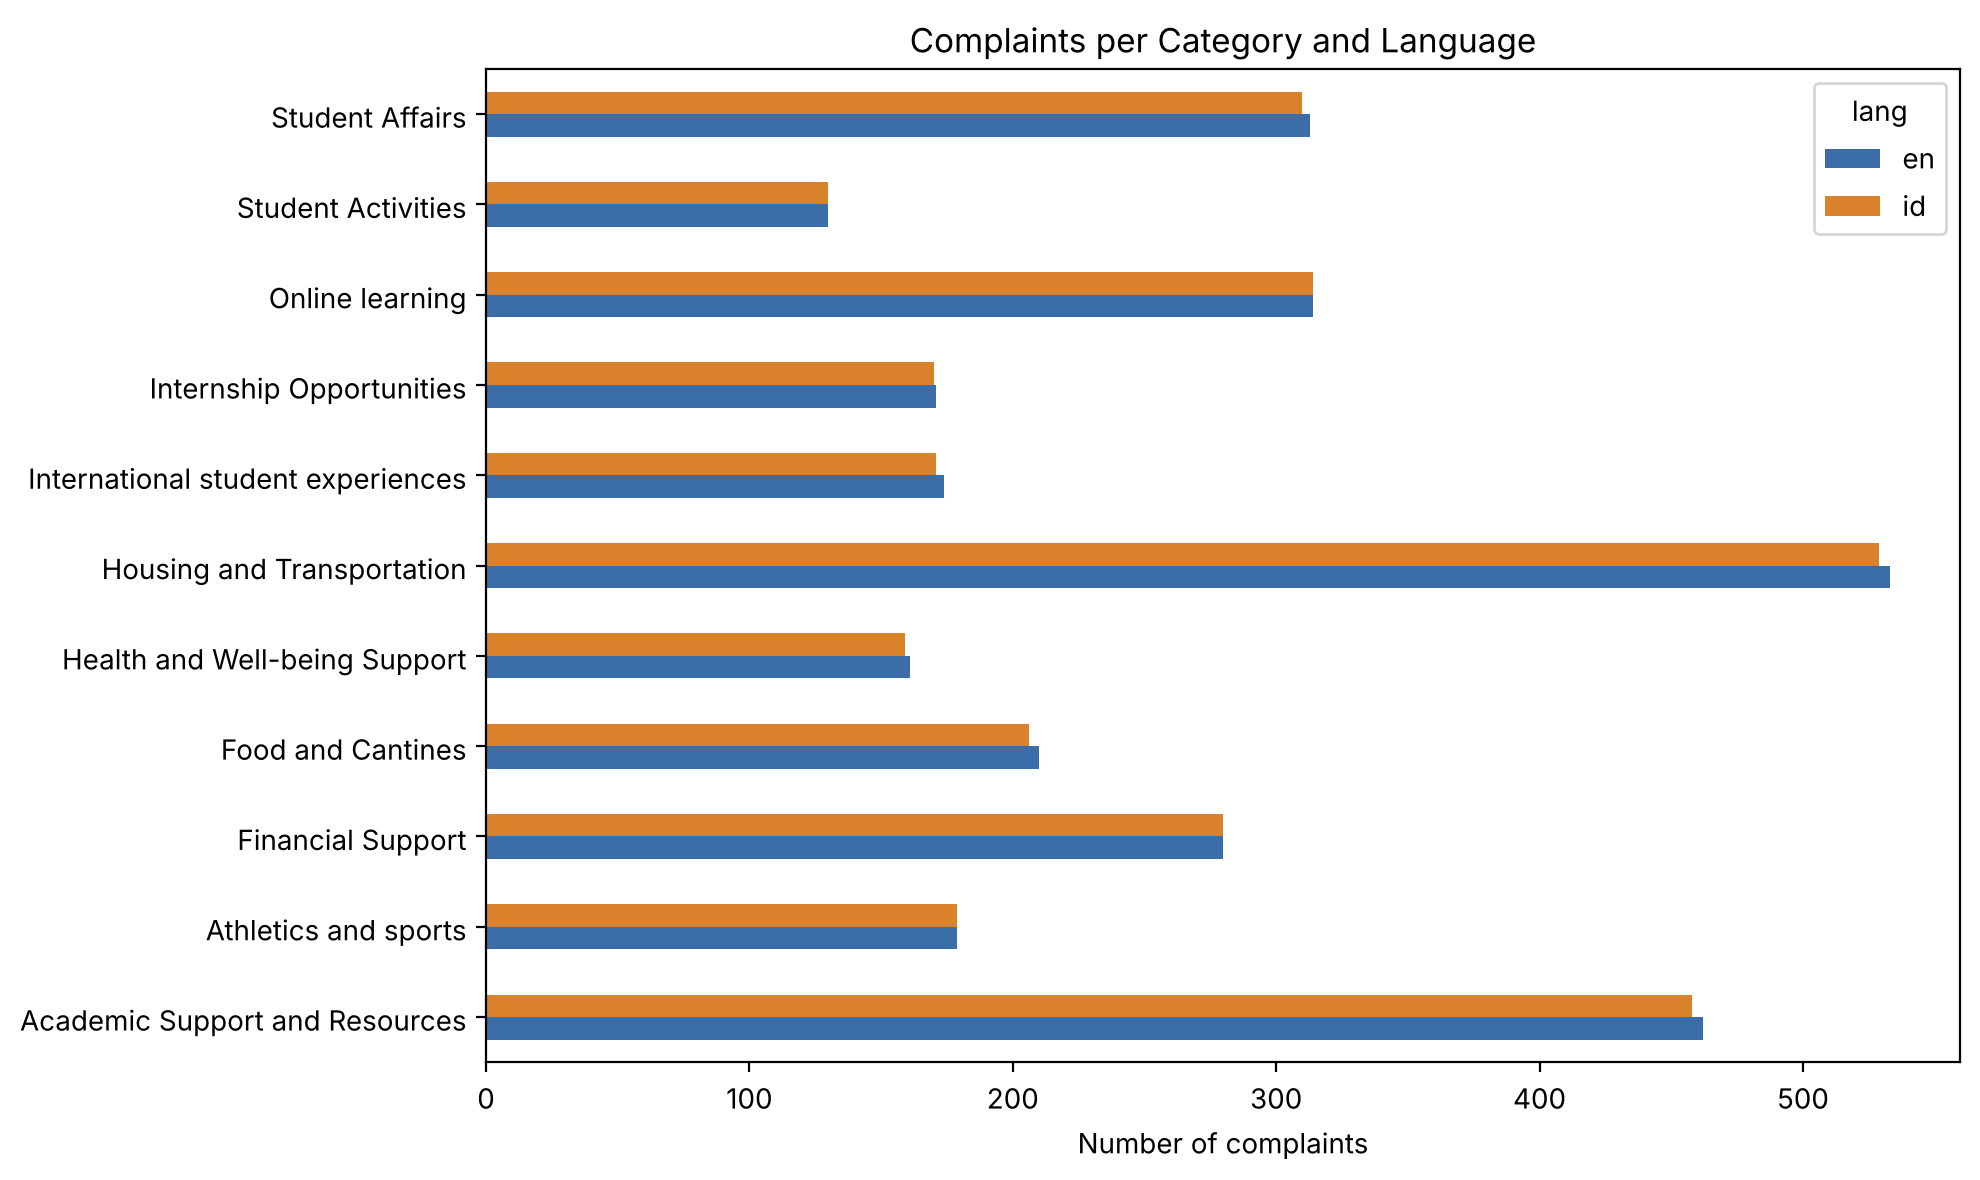

In [3]:
counts = pd.crosstab(data['genre'], data['lang'])
print(counts)

counts.plot(kind='barh', figsize=(10, 6), color=['#3B6EA8', '#D9822B'])
plt.title('Complaints per Category and Language')
plt.xlabel('Number of complaints')
plt.ylabel('')
plt.tight_layout()
plt.show()

## Train/Test Split

80/20 split by complaint group (`StratifiedGroupKFold`, first fold), stratified by category.

In [4]:
splitter = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
train_idx, test_idx = next(splitter.split(data['text'], data['genre'], data['group']))
train, test = data.iloc[train_idx], data.iloc[test_idx]

assert not set(train['group']) & set(test['group']), 'A complaint group leaked across the split'
print(f"Train: {len(train)}  Test: {len(test)}")
print(test['lang'].value_counts())

Train: 4666  Test: 1167
lang
en    585
id    582
Name: count, dtype: int64


## Model

The old pipeline used NLTK's English stopwords and WordNet lemmatizer, which do nothing useful for Indonesian. This version uses two language-neutral feature sets combined:

- **Word n-grams (1–2):** whole words and word pairs, such as "dosen pembimbing" or "financial aid"
- **Character n-grams (2–5):** pieces of words, which handle Indonesian prefixes and suffixes (*di-*, *-kan*, *ber-*), slang spellings, and typos

Both feed one LinearSVC. No custom Python functions are used inside the pipeline, so the saved model loads anywhere with just scikit-learn.

In [5]:
def build_model(C=0.2):
    features = FeatureUnion([
        ('word', TfidfVectorizer(lowercase=True, token_pattern=r'(?u)\b[^\W\d_]{2,}\b',
                                 ngram_range=(1, 2), min_df=2, max_df=0.85, sublinear_tf=True)),
        ('char', TfidfVectorizer(lowercase=True, analyzer='char_wb',
                                 ngram_range=(2, 5), min_df=2, sublinear_tf=True, max_features=60000)),
    ])
    return Pipeline([
        ('features', features),
        ('clf', LinearSVC(C=C, class_weight='balanced', max_iter=5000)),
    ])

model = build_model()
model.fit(train['text'], train['genre'])

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('features', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](11,)","['Academic Support and Resources','Athletics and sports', 'Financial Support',...,'Online learning','Student Activities', 'Student Affairs']"
,"transformer_list transformer_list: list of (str, transformer) tuplesList of transformer objects to be applied to the data. The firsthalf of each tuple is the name of the transformer. The transformer canbe 'drop' for it to be ignored or can be 'passthrough' for features tobe passed unchanged... versionadded:: 1.1 Added the option `""passthrough""`... versionchanged:: 0.22 Deprecated `None` as a transformer in favor of 'drop'.","[('word', ...), ('char', ...)]"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer.Keys are transformer names, values the weights.Raises ValueError if key not present in ``transformer_list``.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, default=TrueIf True, :meth:`get_feature_names_out` will prefix all feature nameswith the name of the transformer that generated that feature.If False, :meth:`get_feature_names_out` will not prefix any featurenames and will error if feature names are not unique... versionadded:: 1.5",True


In [6]:
y_pred = model.predict(test['text'])
print('[Test Set Report — both languages]')
print(classification_report(test['genre'], y_pred))

for lang in ['en', 'id']:
    mask = (test['lang'] == lang).values
    print(f"Macro F1 ({lang}): {f1_score(test['genre'][mask], y_pred[mask], average='macro'):.4f}")

train_f1 = f1_score(train['genre'], model.predict(train['text']), average='macro')
cv_scores = cross_val_score(build_model(), train['text'], train['genre'], groups=train['group'],
                            cv=StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42),
                            scoring='f1_macro')
test_f1 = f1_score(test['genre'], y_pred, average='macro')
gap = train_f1 - cv_scores.mean()

print(f"\nTrain F1 (macro): {train_f1:.4f}")
print(f"CV F1    (macro): {cv_scores.mean():.4f}  (+/- {cv_scores.std():.4f})")
print(f"Test F1  (macro): {test_f1:.4f}")
print(f"Overfit gap (Train-CV): {gap:.4f}")

[Test Set Report — both languages]
                                   precision    recall  f1-score   support

   Academic Support and Resources       0.84      0.78      0.81       184
             Athletics and sports       0.95      0.97      0.96        72
                Financial Support       0.78      0.88      0.82       112
                Food and Cantines       0.93      1.00      0.97        83
    Health and Well-being Support       0.93      0.89      0.91        64
       Housing and Transportation       0.87      0.92      0.89       212
International student experiences       0.81      0.90      0.85        70
         Internship Opportunities       0.86      0.93      0.89        68
                  Online learning       0.92      0.90      0.91       126
               Student Activities       0.87      0.75      0.80        52
                  Student Affairs       0.78      0.65      0.71       124

                         accuracy                           0.8


Train F1 (macro): 0.9952
CV F1    (macro): 0.8768  (+/- 0.0131)
Test F1  (macro): 0.8661
Overfit gap (Train-CV): 0.1184


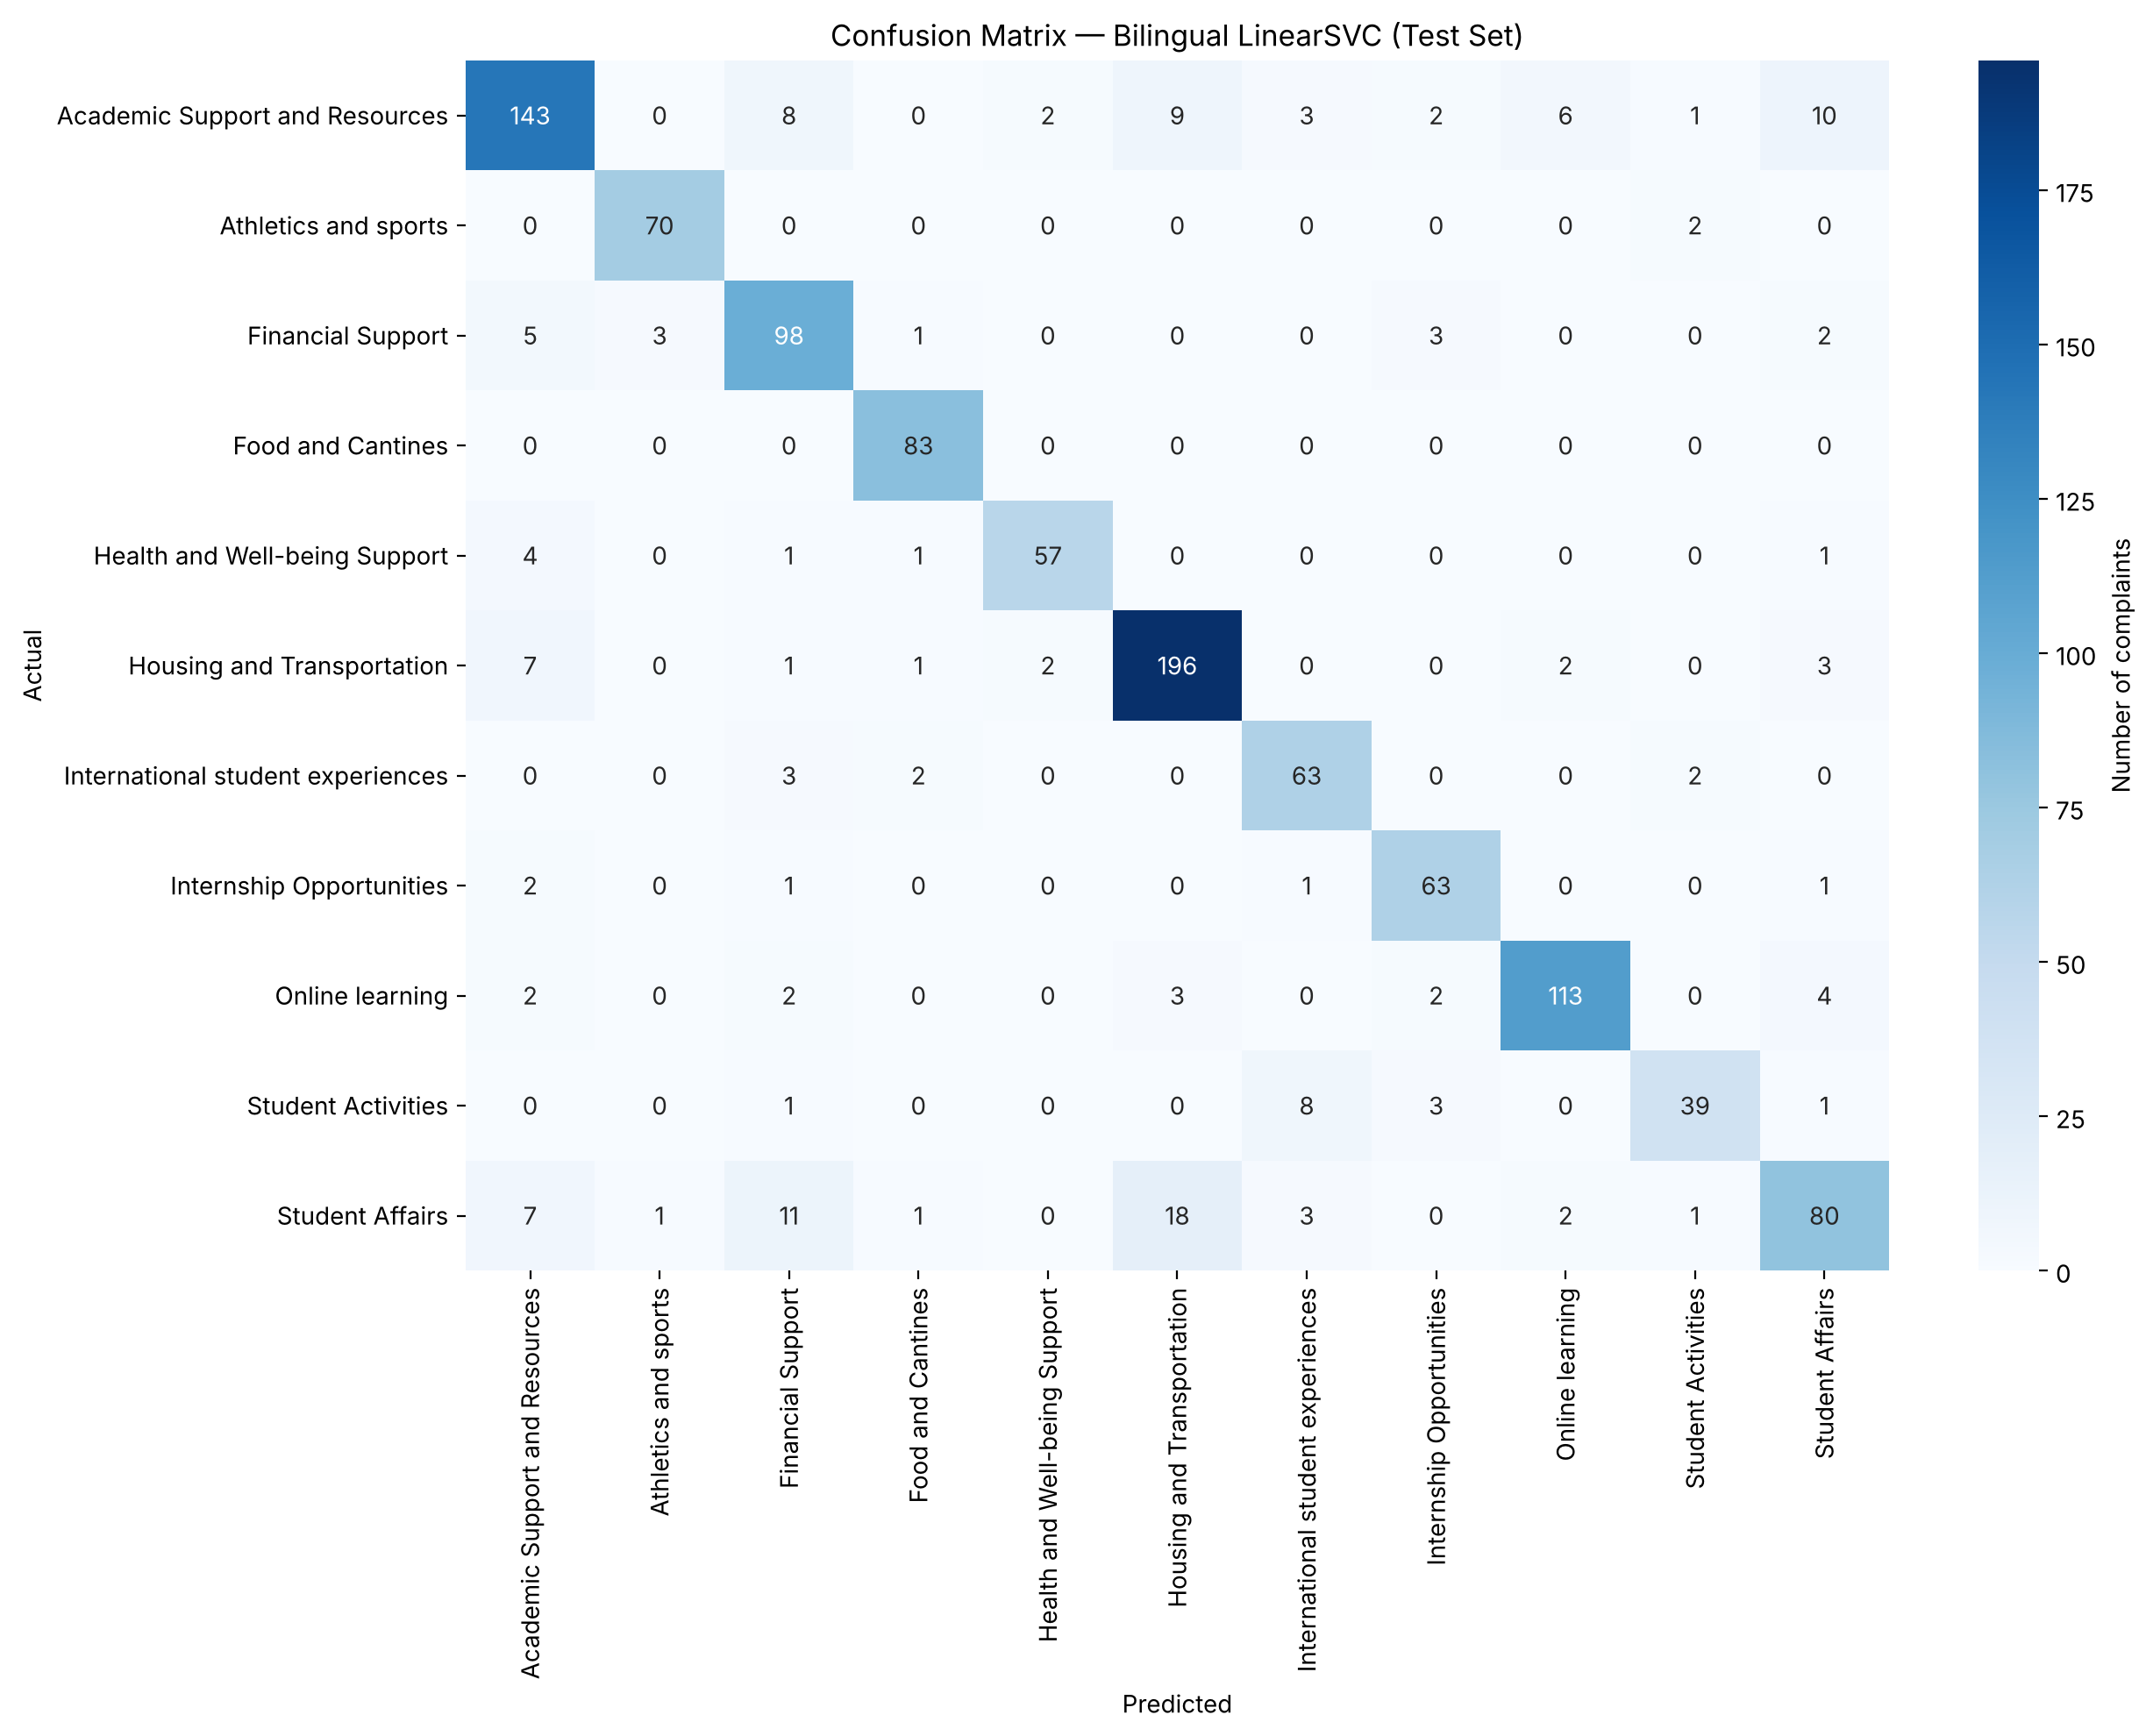

In [7]:
labels_order = sorted(data['genre'].unique())
cm = confusion_matrix(test['genre'], y_pred, labels=labels_order)

plt.figure(figsize=(13, 10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=labels_order, yticklabels=labels_order,
            cbar_kws={'label': 'Number of complaints'})
plt.title('Confusion Matrix — Bilingual LinearSVC (Test Set)')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.show()

### Why the Indonesian data matters

A model trained on English only, then tested on the Indonesian test complaints.

In [8]:
en_only = build_model().fit(train.loc[train['lang'] == 'en', 'text'], train.loc[train['lang'] == 'en', 'genre'])
id_test = test[test['lang'] == 'id']
print(f"English-only model on Indonesian: {f1_score(id_test['genre'], en_only.predict(id_test['text']), average='macro'):.4f}")
print(f"Bilingual model on Indonesian:    {f1_score(id_test['genre'], model.predict(id_test['text']), average='macro'):.4f}")

English-only model on Indonesian: 0.3296
Bilingual model on Indonesian:    0.8693


### Unseen test set (optional)

`test_dataset_1000.csv` is English only, so it checks that adding Indonesian didn't hurt English.

In [9]:
if os.path.exists('test_dataset_1000.csv'):
    unseen = pd.read_csv('test_dataset_1000.csv')
    unseen['Genre'] = standardize_genre(unseen['Genre'])
    unseen_pred = model.predict(unseen['Reports'])
    print(classification_report(unseen['Genre'], unseen_pred))
    print(f"Accuracy: {accuracy_score(unseen['Genre'], unseen_pred):.4f}")
    print(f"Macro F1: {f1_score(unseen['Genre'], unseen_pred, average='macro'):.4f}")
else:
    print('test_dataset_1000.csv not found, skipping')

test_dataset_1000.csv not found, skipping


## Urgency Scoring

Every complaint gets a score from **1 to 10**:

| Score | Level | Meaning |
|---|---|---|
| 1–3 | Minor | General dissatisfaction, suggestions |
| 4–7 | Moderate | Something broken, recurring, ignored, or hurting the student's studies |
| 8–10 | High | Safety, harassment, or health crisis |

The score starts at 1 and adds points for each signal found: safety/crisis words (+7), explicit urgency wording (+2), something broken (+2), impact on studies such as being late for class, missing lectures or an upcoming exam (+2), a long-running or recurring problem (+1), a complaint that was ignored (+1), emotional intensity such as `!` or a shouted word (+1), and a category bonus (+1). A shouted word needs 4+ capital letters and is not a common acronym, so *LMS*, *UTS* or *AC* don't count. Every rule has English and Indonesian keywords, for example *harassment / pelecehan*, *broken / rusak*, *late for class / telat masuk kelas*, *no response / belum ada respon*.

In [9]:
import re

# Each group adds its weight once if any English or Indonesian pattern matches
URGENCY_RULES = [
    # Safety, harassment, health crisis -> any match lands in High (1 + 7 = 8)
    (7, "safety/crisis", [
        r"\bharass(ment|ed|ing)?\b", r"\bassault(ed)?\b", r"\babus(e|ed|ive)\b",
        r"\bthreat(s|en|ened|ening)?\b", r"\bviolen(ce|t)\b", r"\bstalk(ing|ed|er)?\b",
        r"\bfire\b", r"\binjur(y|ed|ies)\b", r"\bunsafe\b", r"\bdanger(ous)?\b",
        r"\bemergency\b", r"\bself[- ]harm\b", r"\bsuicid", r"\bcrisis\b",
        r"\bbleeding\b", r"\bfaint(ed)?\b", r"\bfood poisoning\b", r"\bbull(y|ied|ying)\b",
        # Indonesian
        r"\b(pe|di|me)lecehk?an?\b", r"\bpelecehan\b", r"\bkekerasan\b", r"\b(di)?serang\b",
        r"\bpenyerangan\b", r"\b(di|meng)?ancam(an)?\b", r"\b(di|meng)kuntit\b", r"\bkebakaran\b",
        r"\bterluka\b", r"\bcedera\b", r"\btidak aman\b", r"\b(ber|mem)?bahaya(kan)?\b",
        r"\bdarurat\b", r"\bbunuh diri\b", r"\bmenyakiti diri\b", r"\bkrisis\b",
        r"\bpendarahan\b", r"\bpingsan\b", r"\bkeracunan\b", r"\bperundungan\b", r"\bdi-?bully\b",
    ]),
    # Explicit urgency wording
    (2, "urgent wording", [
        r"\burgent(ly)?\b", r"\bimmediate(ly)?\b", r"\basap\b", r"\bright now\b",
        r"\btoday\b", r"\bdeadline\b",
        r"\bsegera\b", r"\bmendesak\b", r"\bsecepatnya\b", r"\bsekarang juga\b",
        r"\bhari ini\b", r"\btenggat\b",
    ]),
    # Something is broken / unusable
    (2, "breakdown", [
        r"\bbroken\b", r"\bnot working\b", r"\bdoesn'?t work\b", r"\bdown\b",
        r"\bunavailable\b", r"\bglitch(y|es)?\b", r"\bcrash(es|ed|ing)?\b",
        r"\bleak(s|ing)?\b", r"\bno (water|electricity|power|internet|wifi)\b",
        r"\bcan'?t (access|submit|log ?in|enter)\b",
        r"\brusak\b", r"\bmati\b", r"\btidak berfungsi\b", r"\berr?or\b", r"\bbocor\b",
        r"\bgangguan\b", r"\btidak ada (air|listrik|internet|wi-?fi)\b",
        r"\b(tidak|gak|ga|nggak) bisa (diakses|dibuka|diputar|dipakai|digunakan|login|masuk|submit|mengumpulkan|mengakses)\b",
        r"\bcan'?t (be )?(played|opened|used)\b", r"\bwon'?t (play|open|load)\b",
        r"\bout of order\b", r"\btechnical (difficult(y|ies)|issues?|problems?)\b",
    ]),
    # Problem has dragged on
    (1, "prolonged", [
        r"\bweeks?\b", r"\bmonths?\b", r"\brepeatedly\b", r"\bagain\b",
        r"\bstill\b", r"\bdelay(ed|s)?\b", r"\bconstantly\b", r"\bkeeps? happening\b",
        r"\bminggu\b", r"\bbulan\b", r"\bberkali-kali\b", r"\bberulang( kali)?\b",
        r"\bmasih\b", r"\btertunda\b", r"\bterlambat\b", r"\bmolor\b", r"\bterus-menerus\b",
        # recurring problems
        r"\boften\b", r"\bfrequently\b", r"\balways\b", r"\bevery (day|week|time)\b",
        r"\bsering\b", r"\bselalu\b", r"\b(setiap|tiap) (hari|minggu|kali)\b",
    ]),
    # The problem is hurting the student's studies (classes, exams, grades)
    (2, "study impact", [
        r"\blate (for|to) (class|classes|lectures?|exams?)\b",
        r"\bmiss(ed|ing)? (my |the |a )?(first |morning |online )?(class|classes|lectures?|exams?|quiz(zes)?|tests?|deadlines?)\b",
        r"\b(exam|exams|midterms?|finals?|quiz) (is |are )?(tomorrow|next week)\b",
        r"\bcan'?t (attend|join|take) (class|classes|lectures?|the exam|exams?|the quiz)\b",
        r"\baffect(s|ed|ing)? my (grades?|gpa|studies|study|learning)\b",
        r"\b(lose|lost|losing) (marks|points|grades?)\b", r"\bfail(ing)? (the |my )?(course|class|exam)\b",
        r"\b(telat|terlambat) (masuk )?(kelas|kuliah|ujian)\b",
        r"\bketinggalan (kelas|kuliah|materi|ujian|kuis)\b",
        r"\b(tidak|gak|ga|nggak) bisa (ikut|mengikuti) (kelas|kuliah|ujian|kuis|uts|uas)\b",
        r"\bmengganggu (kuliah|perkuliahan|belajar|proses belajar|kegiatan belajar)\b",
        r"\b(nilai|ipk) (saya )?(turun|terancam|jadi jelek)\b",
        r"\b(uts|uas|ujian|kuis) (besok|minggu depan)\b",
        r"\b(memengaruhi|mempengaruhi|berdampak (ke|pada)) (nilai|ipk|kuliah|belajar)\b",
        r"\bdianggap (absen|alpa|tidak hadir)\b",
    ]),
    # Already reported but nobody acted on it
    (1, "ignored", [
        r"\bno (response|reply|resolution|action)\b", r"\bignored\b",
        r"\bnever (been )?fixed\b", r"\bhasn'?t been (fixed|resolved|addressed)\b",
        r"\b(tidak|belum) ada (respon|respons|tanggapan|balasan|tindak lanjut|tindakan)\b",
        r"\bdiabaikan\b", r"\bdicuekin\b",
        r"\b(tidak|belum) (pernah |juga )?(diperbaiki|ditangani|diselesaikan)\b",
    ]),
]

# Small bump for categories where delays tend to hurt students more
CATEGORY_BONUS = {
    "Health and Well-being Support": 1,
    "Student Affairs": 1,
    "Financial Support": 1,
}

COMPILED = [(w, name, re.compile("|".join(p), re.IGNORECASE)) for w, name, p in URGENCY_RULES]

ACRONYMS = {"WIFI", "BINUS", "BINUSMAYA", "KITAS", "BPJS", "SKPI", "ASAP", "HTML", "JAVA"}

def is_shouted(word: str) -> bool:
    core = re.sub(r"[^A-Za-z]", "", word)
    return len(core) >= 4 and core.isupper() and core not in ACRONYMS

def urgency_level(score: int) -> str:
    if score >= 8:
        return "High"
    if score >= 4:
        return "Moderate"
    return "Minor"

def score_urgency(text: str, category: str = None) -> dict:
    """Return an urgency score from 1 to 10, its level, and what triggered it."""
    if not isinstance(text, str) or not text.strip():
        return {"score": 1, "level": "Minor", "reasons": []}

    score, reasons = 1, []
    for weight, name, pattern in COMPILED:
        if pattern.search(text):
            score += weight
            reasons.append(name)

    # Emotional intensity: exclamation marks or shouted words.
    # A shouted word = 4+ capital letters and not a common acronym (LMS, UTS, AC, WIFI, BINUS...).
    if "!" in text or any(is_shouted(w) for w in text.split()):
        score += 1
        reasons.append("intensity")

    if category in CATEGORY_BONUS:
        score += CATEGORY_BONUS[category]
        reasons.append("category")

    score = max(1, min(10, score))
    return {"score": score, "level": urgency_level(score), "reasons": reasons}

In [10]:
# Consistency check: an English complaint and its Indonesian translation should get the same level
en_rows = data[data['lang'] == 'en'].drop_duplicates('group').set_index('group')
id_rows = data[data['lang'] == 'id'].drop_duplicates('group').set_index('group')
shared = en_rows.index.intersection(id_rows.index)
pairs = pd.DataFrame({
    'en': [score_urgency(en_rows.at[g, 'text'], en_rows.at[g, 'genre'])['level'] for g in shared],
    'id': [score_urgency(id_rows.at[g, 'text'], id_rows.at[g, 'genre'])['level'] for g in shared],
})
print(f"Same urgency level in both languages: {(pairs['en'] == pairs['id']).mean():.1%}")
print(pd.crosstab(pairs['en'], pairs['id'], rownames=['English'], colnames=['Indonesian']))


Same urgency level in both languages: 95.9%
Indonesian  High  Minor  Moderate
English                          
High         101      6         4
Minor         11   2596        54
Moderate       3     40        91


lang             en    id
urgency_level            
High            111   115
Minor          2682  2642
Moderate        134   149


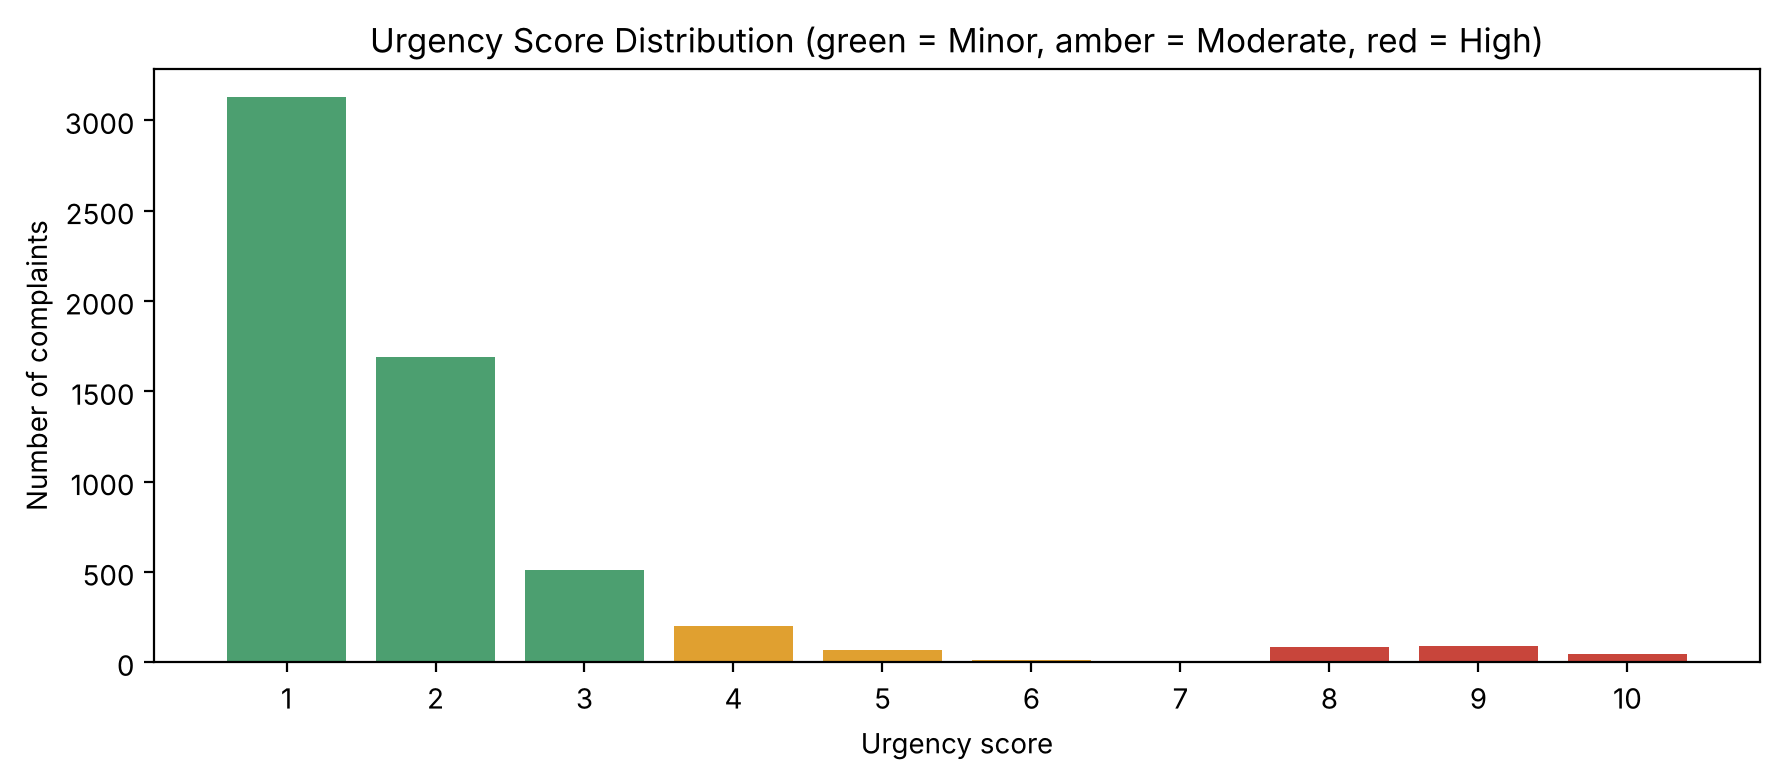

In [11]:
scored = data.apply(lambda r: score_urgency(r['text'], r['genre']), axis=1)
data['urgency_score'] = scored.apply(lambda r: r['score'])
data['urgency_level'] = scored.apply(lambda r: r['level'])

print(pd.crosstab(data['urgency_level'], data['lang']))

fig, ax = plt.subplots(figsize=(9, 4))
dist = data['urgency_score'].value_counts().reindex(range(1, 11), fill_value=0)
ax.bar(dist.index, dist.values, color=['#4C9F70'] * 3 + ['#E0A030'] * 4 + ['#C8453B'] * 3)
ax.set_xticks(range(1, 11))
ax.set_xlabel('Urgency score')
ax.set_ylabel('Number of complaints')
ax.set_title('Urgency Score Distribution (green = Minor, amber = Moderate, red = High)')
plt.tight_layout()
plt.show()

## Department Routing

The classifier picks the category for most complaints. Harassment, violence, and self-harm or medical-crisis complaints are the exception: a keyword override sends them straight to Student Affairs or Health & Counseling in either language, because these are too important to depend on a classifier guess and the dataset has very few examples of them.

In [12]:
# Safety override: these complaints skip the classifier and go straight to the right team,
# so routing doesn't depend on a guess when the data has few examples (English + Indonesian)
SAFETY_ROUTES = [
    ("Student Affairs", re.compile("|".join([
        r"\bharass(ment|ed|ing)?\b", r"\bassault(ed)?\b", r"\babus(e|ed|ive)\b",
        r"\bthreat(s|en|ened|ening)?\b", r"\bviolen(ce|t)\b", r"\bstalk(ing|ed|er)?\b",
        r"\bbull(y|ied|ying)\b", r"\bdiscriminat",
        r"\b(pe|di|me)lecehk?an?\b", r"\bpelecehan\b", r"\bkekerasan\b", r"\b(di|meng)?ancam(an)?\b",
        r"\b(di|meng)kuntit\b", r"\bperundungan\b", r"\bdi-?bully\b", r"\bdiskriminasi\b",
    ]), re.IGNORECASE)),
    ("Health and Well-being Support", re.compile("|".join([
        r"\bself[- ]harm\b", r"\bsuicid", r"\bfaint(ed)?\b", r"\bbleeding\b",
        r"\bbunuh diri\b", r"\bmenyakiti diri\b", r"\bpingsan\b", r"\bpendarahan\b",
    ]), re.IGNORECASE)),
]

def safety_category(text: str):
    for category, pattern in SAFETY_ROUTES:
        if pattern.search(text):
            return category
    return None

department_map = {
    "Academic Support and Resources":     "Academic Affairs Office",
    "Athletics and sports":               "Sports & Recreation Center",
    "Financial Support":                  "Finance / Scholarship Office",
    "Food and Cantines":                  "Campus Services (Food & Facilities)",
    "Health and Well-being Support":      "Health & Counseling Center",
    "Housing and Transportation":         "Facilities & Housing Office",
    "International student experiences":  "International Student Office",
    "Internship Opportunities":           "Career Center",
    "Online learning":                    "IT / Learning Management Support",
    "Student Activities":                 "Student Activities Office",
    "Student Affairs":                    "Student Affairs Office",
}

def classify_and_route(complaint: str, verbose: bool = True):
    """Classify a complaint (English or Indonesian), score its urgency, and route it."""
    if not complaint or not complaint.strip():
        return None

    override = safety_category(complaint)
    category = override or model.predict([complaint])[0]
    department = department_map.get(category, "General Office (unmapped category)")
    urgency = score_urgency(complaint, category)

    if verbose:
        print("=" * 60)
        print(f"  Complaint:  {complaint}")
        print(f"  Category:   {category}" + ("  (safety override)" if override else ""))
        print(f"  Urgency:    {urgency['score']}/10 ({urgency['level']})")
        print(f"  Routed to:  {department}")

    return {
        "category": category,
        "safety_override": override is not None,
        "department": department,
        "urgency_score": urgency["score"],
        "urgency_level": urgency["level"],
    }

In [13]:
examples = [
    "The gym isn't cleaned regularly.",
    "The library chair is broken for months now, why hasn't it been fixed yet?",
    "A senior keeps harassing me after class and I feel unsafe.",
    "Gym tidak dibersihkan secara rutin.",
    "Kursi perpustakaan rusak sudah berbulan-bulan, kenapa belum juga diperbaiki?",
    "LMS down dan saya gak bisa submit tugas sebelum deadline hari ini!",
    "Pencairan beasiswa saya masih tertunda berminggu-minggu dan belum ada respon.",
    "Ada senior yang terus melecehkan saya setelah kelas dan saya merasa tidak aman.",
    "Makanan di kantin mahal banget dan porsinya kecil.",
]
results = [classify_and_route(c) for c in examples]

  Complaint:  The gym isn't cleaned regularly.
  Category:   Athletics and sports
  Urgency:    1/10 (Minor)
  Routed to:  Sports & Recreation Center
  Complaint:  The library chair is broken for months now, why hasn't it been fixed yet?
  Category:   Academic Support and Resources
  Urgency:    4/10 (Moderate)
  Routed to:  Academic Affairs Office
  Complaint:  A senior keeps harassing me after class and I feel unsafe.
  Category:   Student Affairs  (safety override)
  Urgency:    9/10 (High)
  Routed to:  Student Affairs Office
  Complaint:  Gym tidak dibersihkan secara rutin.
  Category:   Athletics and sports
  Urgency:    1/10 (Minor)
  Routed to:  Sports & Recreation Center
  Complaint:  Kursi perpustakaan rusak sudah berbulan-bulan, kenapa belum juga diperbaiki?
  Category:   Academic Support and Resources
  Urgency:    5/10 (Moderate)
  Routed to:  Academic Affairs Office
  Complaint:  LMS down dan saya gak bisa submit tugas sebelum deadline hari ini!
  Category:   Online learn

In [14]:
# Staff priority queue: highest urgency first
queue = pd.DataFrame(results)
queue['complaint'] = examples
queue = queue.sort_values('urgency_score', ascending=False)
print(queue[['urgency_score', 'urgency_level', 'department', 'complaint']].to_string(index=False))

 urgency_score urgency_level                          department                                                                       complaint
             9          High              Student Affairs Office                      A senior keeps harassing me after class and I feel unsafe.
             9          High              Student Affairs Office Ada senior yang terus melecehkan saya setelah kelas dan saya merasa tidak aman.
             6      Moderate    IT / Learning Management Support              LMS down dan saya gak bisa submit tugas sebelum deadline hari ini!
             5      Moderate             Academic Affairs Office    Kursi perpustakaan rusak sudah berbulan-bulan, kenapa belum juga diperbaiki?
             4      Moderate        Finance / Scholarship Office   Pencairan beasiswa saya masih tertunda berminggu-minggu dan belum ada respon.
             4      Moderate             Academic Affairs Office       The library chair is broken for months now, why hasn't it b

## Save the Final Model

After evaluation, retrain on **all** the data and save it for the app. Loading it only needs scikit-learn and joblib:

```python
model = joblib.load('siap_classifier.joblib')
model.predict(["Wifi asrama mati dari kemarin"])
```

In [15]:
final_model = build_model().fit(data['text'], data['genre'])
joblib.dump(final_model, 'siap_classifier.joblib')
print(f"Saved siap_classifier.joblib ({os.path.getsize('siap_classifier.joblib') / 1e6:.1f} MB)")

Saved siap_classifier.joblib (7.7 MB)
